# 04 · MODIS reproduction: do the gains hold on 2020→2024?

Every result in notebooks 01–03 forecasts 2015→2020. The
intern *looked at* 2020 after every round, so the write-up itself calls those results retrospective. 
One interval never informed any choice: **2020→2024**. Rerunning the identical
method one interval later answers the question that matters before porting it:
**does the improvement hold on other period that was not tuned on?**

**Design.** The intern's code hard-codes its years (history 2001/2005/2010/2015,
target 2020). Instead of editing it, the notebook runs it on a copy of `data/`
in which every real map sits one slot earlier:

| Role in the code | Variable name in the code | Real map |
|---|---|---|
| Earliest history | 2001 | 2005 |
| Initial fit start | 2005 | 2010 |
| Validation start / refit start | 2010 | 2015 |
| Forecast start | 2015 | 2020 |
| Forecast target | 2020 | **2024** |

So every model and threshold is chosen on 2015→2020 data and scored
once on 2024.

**Limits of this test:**
1. **Horizon.** The real final step is 4 years (2020→2024), but the code assumes
   5. Fixed-demand allocation therefore applies a 5-year quantity of change.
   Section 4 checks how much this matters.
2. **Lag label.** In the first fitting stage (before validation), the code labels the
   history lag "4 years" (2001→2005), but the real lag is 5 (2005→2010). This affects one
   history feature in that stage only.
3. **Was 2024 opened before?** Yes, in notebooks 01 and 03, for diagnostics only
   (label reversion, the cleaned reference), never to choose anything.

In [1]:
import sys; sys.path.insert(0, "../scripts")              # shared code: landuse_experiments/scripts/
import nb_helpers as H
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "figure.facecolor": H.SURFACE})
RERUN = False   # ~1 hour for all rounds below
f, a = "figure_of_merit_pct", "overall_accuracy"
H.prepare_shifted_data().pipe(H.show, 0)

File name the code reads,Real map it contains,SHA-256 (first 12)
Guinea_LandCover_2001.tif,Guinea_LandCover_2005.tif,92ebfdbebd9d
Guinea_LandCover_2005.tif,Guinea_LandCover_2010.tif,de82d24fd61e
Guinea_LandCover_2010.tif,Guinea_LandCover_2015.tif,656cd56f7bd9
Guinea_LandCover_2015.tif,Guinea_LandCover_2020.tif,5e010260aa2a
Guinea_LandCover_2020.tif,Guinea_LandCover_2024.tif,4dd67d6c300f


## 1 · Run the identical rounds on the shifted maps

In [2]:
O = H.SHIFT_OUTPUTS
steps = {  # run name: (module, function, extra arguments)
    "controlled_2010_2015_2020": ("controlled", "run_controlled_comparison", ", make_plot=False"),
    "local_comparison_2010_2015_2020": ("comparison", "run_comparison", ", sampling='legacy_balanced', make_plot=False"),
    "improvements_20260909": ("improvements", "run_improvements", ", make_plot=False"),
    "advanced_20260909": ("advanced", "run_advanced", ", make_plot=False"),
    "actions_20260909": ("advanced", "run_advanced",
                         ", make_plot=False, candidates=__import__('local_landuse.actions', fromlist=['CANDIDATES']).CANDIDATES"),
    "temporal_memory_20260909": ("temporal_memory", "run_memory", ""),
}
shifted = {name: H.ensure_shifted_run(name, *spec, rerun=RERUN) for name, spec in steps.items()}
shifted["fom40_summary_20260909"] = H.ensure_shifted_run(
    "fom40_summary_20260909", "advanced_summary", "summarize_runs",
    f", run_directories=[r'{shifted['advanced_20260909']}', r'{shifted['actions_20260909']}']", rerun=RERUN)

t24 = H.read_csv(shifted["controlled_2010_2015_2020"] / "temporal_holdout/comparison.csv")
print(f"Evaluation pixels: {int(t24['pixels'].iloc[0]):,} (same footprint as 2015→2020: 992,833)")
print(f"Observed changes 2020→2024: {int(t24['observed_change_pixels'].iloc[0]):,} "
      f"= {100 * t24['observed_change_pixels'].iloc[0] / t24['pixels'].iloc[0]:.2f}%   (2015→2020: 75,365 = 7.59%)")

Using saved run: outputs/test_2020_2024/outputs/controlled_2010_2015_2020
Using saved run: outputs/test_2020_2024/outputs/local_comparison_2010_2015_2020
Using saved run: outputs/test_2020_2024/outputs/improvements_20260909
Using saved run: outputs/test_2020_2024/outputs/advanced_20260909
Using saved run: outputs/test_2020_2024/outputs/actions_20260909
Using saved run: outputs/test_2020_2024/outputs/temporal_memory_20260909
Using saved run: outputs/test_2020_2024/outputs/fom40_summary_20260909
Evaluation pixels: 992,833 (same footprint as 2015→2020: 992,833)
Observed changes 2020→2024: 73,978 = 7.45%   (2015→2020: 75,365 = 7.59%)


## 2 · Results: 2015→2020 against 2020→2024

Both columns come from the identical code. The 2015→2020 column is our rerun
from notebook 01; the 2020→2024 column is new. "Validation-selected" rows are
the model each round froze *before* reading its target map, so they are the
honest numbers. Other rows are shown for context.

In [3]:
def load(root):
    c = H.read_csv(root["controlled_2010_2015_2020"] / "temporal_holdout/comparison.csv")
    l = H.read_csv(root["local_comparison_2010_2015_2020"] / "comparison.csv")
    imp = H.read_csv(root["improvements_20260909"] / "final_comparison.csv")
    sel_imp = json.loads((root["improvements_20260909"] / "frozen_selection.json").read_text())["model"]["name"]
    adv = H.read_csv(root["fom40_summary_20260909"] / "comparison.csv")
    sel_adv = adv.loc[adv["selected"].astype(str) == "True", "name"].iloc[0]
    tm = H.read_csv(root["temporal_memory_20260909"] / "final_comparison.csv")
    sel_tm = json.loads((root["temporal_memory_20260909"] / "report.json").read_text())["selected_model"]
    return {
        "Original-style transition RF": H.row(l, "model", "transition_rf_allocation", f),
        "Binary RF, shared samples": H.row(c, "model", "binary_rf_allocation", f),
        "Multiclass RF, shared samples": H.row(c, "model", "multiclass_rf_allocation", f),
        "RF + history": H.row(imp, "name", "rf_history", f),
        "Shallow XGBoost + all features": H.row(imp, "name", "xgb_shallow", f),
        "History round, validation-selected + tuned allocation": H.row(imp, "name", "selected_with_allocation_change", f),
        "Change-focused round, validation-selected": H.row(adv, "name", sel_adv, f),
        "Longer-history RF control": H.row(tm, "name", "recent_two_stage_rf_control", f),
        "Longer-history round, validation-selected": H.row(tm, "name", sel_tm, f),
    }, {"History round": sel_imp, "Change-focused round": sel_adv, "Longer-history round": sel_tm}

orig = {name: H.OUTPUTS / name for name in list(steps) + ["fom40_summary_20260909"]}
r20, s20 = load(orig)
r24, s24 = load(shifted)
table = pd.DataFrame({"Configuration": list(r20), "2015→2020 FoM %": list(r20.values()),
                      "2020→2024 FoM %": [r24[k] for k in r20]})
base20, base24 = r20["Original-style transition RF"], r24["Original-style transition RF"]
table["Gain over original, 2015→2020"] = table["2015→2020 FoM %"] - base20
table["Gain over original, 2020→2024"] = table["2020→2024 FoM %"] - base24
H.show(table)

Configuration,2015→2020 FoM %,2020→2024 FoM %,"Gain over original, 2015→2020","Gain over original, 2020→2024"
Original-style transition RF,20.00,19.80,0.00,0.00
"Binary RF, shared samples",20.29,19.48,0.29,-0.33
"Multiclass RF, shared samples",20.82,20.38,0.82,0.58
RF + history,22.93,22.41,2.93,2.60
Shallow XGBoost + all features,24.01,22.74,4.01,2.94
"History round, validation-selected + tuned allocation",24.14,23.72,4.14,3.91
"Change-focused round, validation-selected",25.88,24.22,5.88,4.41
Longer-history RF control,26.84,23.60,6.84,3.79
"Longer-history round, validation-selected",26.08,25.00,6.08,5.20


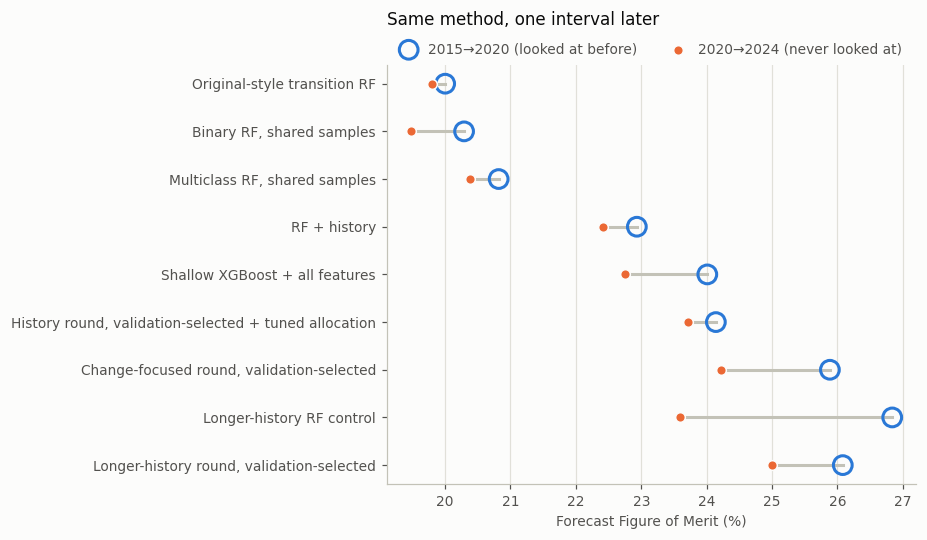

In [4]:
H.plot_dumbbell(table, "Same method, one interval later", left="2015→2020 FoM %", right="2020→2024 FoM %",
                labels=("2015→2020 (looked at before)", "2020→2024 (never looked at)"),
                xlabel="Forecast Figure of Merit (%)")
plt.tight_layout(); plt.show()

**What validation chose in each run.** Only the three rounds with a selection step appear: the model chosen for the 2015→2020 forecast and for the 2020→2024 forecast. The selections are made on a different
validation period in each run, so they need not agree. Agreement would show the
choice is stable; disagreement shows which choices are fragile.

In [5]:
H.show(pd.DataFrame([(k, s20[k], s24[k], "same" if s20[k] == s24[k] else "different") for k in s20],
                    columns=["Round", "Selected for 2015→2020", "Selected for 2020→2024", ""]))

Round,Selected for 2015→2020,Selected for 2020→2024,
History round,rf_history,xgb_shallow,different
Change-focused round,two_stage_rf,xgb_context,different
Longer-history round,pooled_memory_joint_xgb,pooled_memory_joint_xgb,same


## 3 · Model-free rules on 2020→2024

Built with the intern's own `build_rules` function from labels up to 2020 only, and scored on the same pixels.

In [6]:
import sys, rasterio
sys.path.insert(0, str(H.INTERN))          # the intern's package (local_landuse/), imported read-only
from local_landuse.trivial_rules import build_rules, neighbourhood_majority
from local_landuse.advanced import compact_metrics
maps = {slot: H.read_map(f"Guinea_LandCover_{real}.tif")[0] for slot, real in H.SHIFT.items()}
with rasterio.open(shifted["controlled_2010_2015_2020"] / "temporal_holdout/evaluation_mask.tif") as src:
    mask = src.read(1).astype(bool)
history = {slot: maps[slot][mask] for slot in (2001, 2005, 2010, 2015)}
classes = np.unique(np.concatenate(list(history.values())))
nm = neighbourhood_majority(maps[2015], classes)[mask]
nm8 = neighbourhood_majority(maps[2015], classes, include_self=False)[mask]
start, observed = history[2015], maps[2020][mask]
rule_rows = []
for name, predicted in build_rules(history, nm, classes, nm8).items():
    m = compact_metrics(start, observed, predicted, predicted != start)
    rule_rows.append((name.replace("2015", "2020").replace("2010", "2015").replace("2005", "2010")
                      .replace("2001", "2005"), m[f], 100 * m[a]))
rules24 = pd.DataFrame(rule_rows, columns=["Rule (real years)", "2020→2024 FoM %", "Accuracy %"])
H.show(rules24)

Rule (real years),2020→2024 FoM %,Accuracy %
Every pixel takes the majority class of its eight 2020 neighbours,19.84,90.50
Every pixel takes the majority class of its 2020 3x3 window,18.34,91.31
Previous changers take the majority class of their eight 2020 neighbours,13.88,92.15
Revert to the 2015 class if changed 2015->2020,17.54,89.69
Revert to the 2010 class if changed 2015->2020,14.42,90.78
Revert to the modal 2005-2020 class if changed 2015->2020,14.45,90.91
Continue: previous changers move to their class's most likely destination,12.72,89.09
Revert to the modal class if changed twice (2010->2015 and 2015->2020),1.78,92.37
No change,0.00,92.55


## 4 · Does the 4-year horizon distort the comparison?

Fixed-demand allocation applies a quantity of change estimated from a 5-year
interval. If 2020→2024 had far less change than a 5-year interval, the models
would be penalised for over-predicting it.

In [7]:
c24 = H.read_csv(shifted["controlled_2010_2015_2020"] / "temporal_holdout/comparison.csv")
c20 = H.read_csv(H.OUTPUTS / "controlled_2010_2015_2020" / "temporal_holdout/comparison.csv")
H.show(pd.DataFrame([
    ("2015→2020 (5 years)", int(c20["observed_change_pixels"].iloc[0]),
     int(H.row(c20, "model", "multiclass_rf_allocation", "predicted_change_pixels"))),
    ("2020→2024 (4 years)", int(c24["observed_change_pixels"].iloc[0]),
     int(H.row(c24, "model", "multiclass_rf_allocation", "predicted_change_pixels"))),
], columns=["Interval", "Observed changed pixels", "Allocated by fixed demand"]), 0)

Interval,Observed changed pixels,Allocated by fixed demand
2015→2020 (5 years),75365,67954
2020→2024 (4 years),73978,68796


Observed change over the 4-year interval is almost the same as over the 5-year
one, and the allocated quantity sits below it in both. Label churn sets the
amount of change on this product more than elapsed time does, so assuming 5
years does not inflate false alarms here.

---

## Summary

In [8]:
honest = table[table["Configuration"].str.contains("validation-selected|Original-style")]
for _, r in honest.iterrows():
    print(f"{r['Configuration']:58s} 2015→2020 {r['2015→2020 FoM %']:6.2f}%   2020→2024 {r['2020→2024 FoM %']:6.2f}%"
          f"   gain {r['Gain over original, 2020→2024']:+.2f}")
nm24 = rules24.iloc[0]["2020→2024 FoM %"]
print(f"\nEight-neighbour majority rule, 2020→2024: {nm24:.2f}%  (original-style RF: {base24:.2f}%)")

Original-style transition RF                               2015→2020  20.00%   2020→2024  19.80%   gain +0.00
History round, validation-selected + tuned allocation      2015→2020  24.14%   2020→2024  23.72%   gain +3.91
Change-focused round, validation-selected                  2015→2020  25.88%   2020→2024  24.22%   gain +4.41
Longer-history round, validation-selected                  2015→2020  26.08%   2020→2024  25.00%   gain +5.20

Eight-neighbour majority rule, 2020→2024: 19.84%  (original-style RF: 19.80%)


**Verdict: most of the improvement are validated on the unseen interval.** Every
validation-selected configuration still beats the original-style method on
2020→2024, by **+3.9 to +5.2 points** (2015→2020: +4.1 to +6.1). Absolute scores
are 0.4–1.7 points lower, which is normal for a period nothing was tuned on.

| Finding | 2015→2020 | 2020→2024 | Holds? |
|---|---:|---:|---|
| History features over the same-sample baseline (`rf_history` − `rf_baseline`) | +2.1 | +2.0 | **Yes, unchanged.** The strongest candidate to port |
| History round, validation-selected + tuned allocation, over original | +4.1 | +3.9 | Yes |
| Change-focused round (thresholds, two-stage), over original | +5.9 | +4.4 | Mostly. A quarter of the gain is lost |
| Longer-history round, over original | +6.1 | +5.2 | Yes |
| Neighbour-majority rule (no model) over original | +2.7 | **+0.0** | **Does not repeat.** On 2024 it only ties the original-style method |

Three details:
* **The model-free rule's advantage is interval-specific.** On 2015→2020 it beat
  the original-style method by 2.7 points; on 2020→2024 the two tie (19.84% vs
  19.80%). The rule is still the right first check on ESRI, but a single interval
  is not enough to conclude a learned model is no better than it.
* **Selections change between runs.** Validation picks a different winner in
  two of three rounds. The *gain* is stable; the exact winner is not. So the ESRI
  port should carry over feature families and model averaging rather than one
  named model.
* **Thresholds tuned on validation transfer less well than features.** The
  change-focused round lost 1.5 points of its gain, and the longer-history RF
  control, which also uses selected thresholds, fell from 26.84% to 23.60%. The
  history *features* lost nothing. For ESRI, where the deployed module is given the
  amount of change, features are the safer thing to port.

**Not covered here:** the satellite families and the 28.25% probability ensemble
on 2020→2024. They would need 2020 MODIS/Landsat downloads and about six hours of
model fitting. Both ideas are tested on the deployed ESRI product instead (notebook 06 and notebook 07).

In [9]:
out = H.SUMMARY; out.mkdir(parents=True, exist_ok=True)
table.to_csv(out / "04_2020_2024_vs_2015_2020.csv", index=False)
rules24.to_csv(out / "04_model_free_rules_2020_2024.csv", index=False)
print("Saved tables to", out.relative_to(H.ROOT))

Saved tables to outputs\summary
